# RWA redemption analysis

This notebook analyzes the redeems in `redemptions.csv`. Each token has a separate section. The last section shows only the instant redeems of each token.

Redeem types:

- An instant redeem pays out in the same transaction.
- A request redeem pays out later, after the issuer processes the request.

Data rules:

- The notebook uses only redeems with an `amount_usd` value of 100 USD or more.
- All times are in UTC.
- The "last 12 months" period ends with the month of the latest redeem in the data. This last month can be incomplete.
- The "average number of redeems" for a month is the number of redeems divided by the number of days in that month.
- For the last month, the notebook divides by the number of days up to the latest redeem.

## Setup

This cell loads the data, applies the 100 USD limit and defines the shared functions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter, MaxNLocator

MIN_USD = 100
PERCENTILES = [0.20, 0.50, 0.95, 0.99]
TOKENS = ["USTB", "USCC", "mTBILL", "mWIN", "BUIDL"]
BAR_COLOR = "#2a78d6"

# The notebook lives in output/, next to the CSV. The second path works when the kernel starts at the repo root.
DATA = next(p for p in [Path("redemptions.csv"), Path("output/redemptions.csv")] if p.exists())

raw = pd.read_csv(DATA, parse_dates=["timestamp"])
df = raw[raw["amount_usd"] >= MIN_USD].copy()
utc = df["timestamp"].dt.tz_convert("UTC").dt.tz_localize(None)
df["month"] = utc.dt.to_period("M")
df["hour"] = utc.dt.hour

END = utc.max()
MONTHS = pd.period_range(END.to_period("M") - 11, END.to_period("M"), freq="M")
DAYS = pd.Series([m.days_in_month for m in MONTHS], index=MONTHS)
DAYS.iloc[-1] = END.day  # the last month counts only the days up to the latest redeem

missing = sorted(set(df["token"]) - set(TOKENS))
print(f"Rows in CSV: {len(raw):,}. Rows with amount_usd >= {MIN_USD} USD: {len(df):,}.")
print(f"Last 12 months: {MONTHS[0]} to {MONTHS[-1]} (data ends {END:%Y-%m-%d %H:%M} UTC).")
print(f"Tokens without a section: {missing or 'none'}")

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})


def usd(x, _pos=None):
    for div, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if abs(x) >= div:
            return f"${x / div:,.1f}{suffix}"
    return f"${x:,.0f}"


def bar(labels, values, title, ylabel, money=False, integer=False):
    fig, ax = plt.subplots()
    ax.bar(labels, values, color=BAR_COLOR, width=0.7)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    if money:
        ax.yaxis.set_major_formatter(FuncFormatter(usd))
    if integer:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    if isinstance(labels[0], str):  # month labels need rotation, hour numbers do not
        ax.tick_params(axis="x", labelrotation=45)
    else:
        ax.set_xticks(labels)
    fig.tight_layout()
    plt.show()


def token_rows(token, kind=None):
    """Redeems of one token. kind="instant" (or "request") keeps only that redemption_type."""
    t = df[df["token"] == token]
    return t if kind is None else t[t["redemption_type"] == kind]


def overall(token, kind=None):
    s = token_rows(token, kind)["amount_usd"]
    if s.empty:
        print(f"{token}: the data has no {kind + ' ' if kind else ''}redeems of {MIN_USD} USD or more.")
        return
    stats = {"Redeems (count)": f"{len(s):,}", "Average": usd(s.mean()), "Std": usd(s.std()), "Min": usd(s.min())}
    for p in PERCENTILES:
        stats[f"P{p * 100:.0f}"] = usd(s.quantile(p))
    stats["Max"] = usd(s.max())
    display(pd.DataFrame({"Value": stats}))


def monthly(token, kind=None):
    t = token_rows(token, kind)
    g = t[t["month"].isin(MONTHS)].groupby("month")["amount_usd"]
    m = pd.DataFrame(index=MONTHS)
    m["redeems"] = g.size().reindex(MONTHS, fill_value=0)
    m["days"] = DAYS
    m["avg_redeems_per_day"] = m["redeems"] / m["days"]
    m["avg_amount_usd"] = g.mean().reindex(MONTHS)
    m["total_amount_usd"] = g.sum().reindex(MONTHS, fill_value=0)
    m["label"] = [p.strftime("%b %Y") for p in MONTHS]
    return m


def show_monthly_table(m):
    table = pd.DataFrame({
        "Redeems": m["redeems"],
        "Days": m["days"],
        "Avg redeems / day": m["avg_redeems_per_day"].map("{:.2f}".format),
        "Avg amount": m["avg_amount_usd"].map(lambda v: usd(v) if pd.notna(v) else "-"),
        "Total amount": m["total_amount_usd"].map(usd),
    })
    table.index = m["label"]
    display(table)


def hourly(token, kind=None):
    return token_rows(token, kind).groupby("hour").size().reindex(range(24), fill_value=0)

Rows in CSV: 19,562. Rows with amount_usd >= 100 USD: 14,930.
Last 12 months: 2025-12 to 2026-11 (data ends 2026-11-17 21:27 UTC).
Tokens without a section: none


## USTB (Superstate)

### USTB: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [2]:
overall("USTB")

,Value
Redeems (count),"9,928"
Average,$625.7K
Std,$5.5M
Min,$100
P20,$1.5K
P50,$18.1K
P95,$2.0M
P99,$10.0M
Max,$303.1M


### USTB: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [3]:
m = monthly("USTB")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,355,31,11.45,$765.8K,$271.9M
Jan 2026,434,31,14.00,$270.9K,$117.6M
Feb 2026,641,28,22.89,$598.5K,$383.6M
Mar 2026,451,31,14.55,$1.0M,$465.4M
Apr 2026,216,30,7.20,$3.0M,$645.4M
May 2026,406,31,13.10,$1.3M,$547.6M
Jun 2026,636,30,21.20,$1.2M,$737.3M
Jul 2026,538,31,17.35,$467.6K,$251.6M
Aug 2026,685,31,22.10,$506.9K,$347.2M


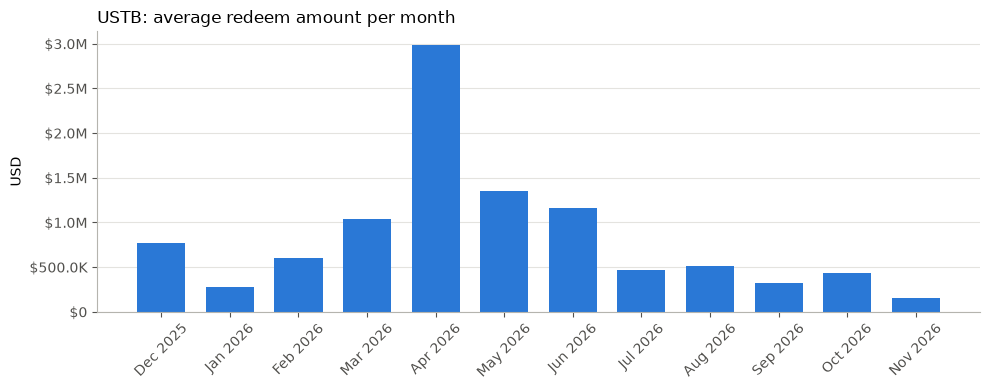

In [4]:
bar(m["label"].tolist(), m["avg_amount_usd"], "USTB: average redeem amount per month", "USD", money=True)

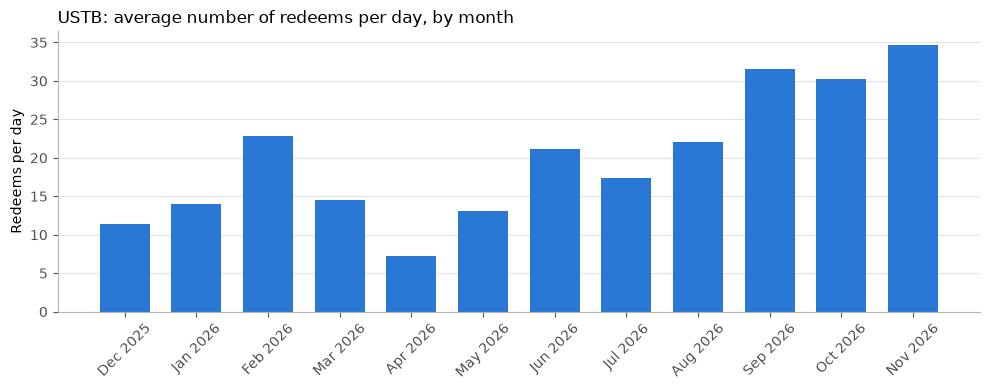

In [5]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "USTB: average number of redeems per day, by month", "Redeems per day")

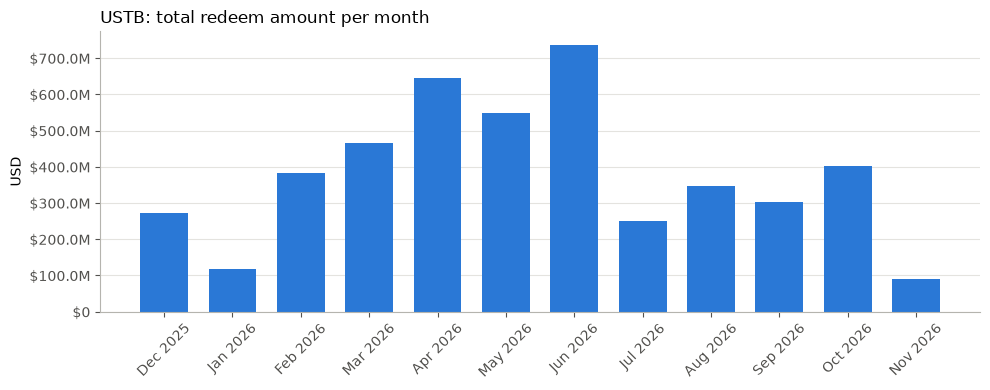

In [6]:
bar(m["label"].tolist(), m["total_amount_usd"], "USTB: total redeem amount per month", "USD", money=True)

### USTB: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

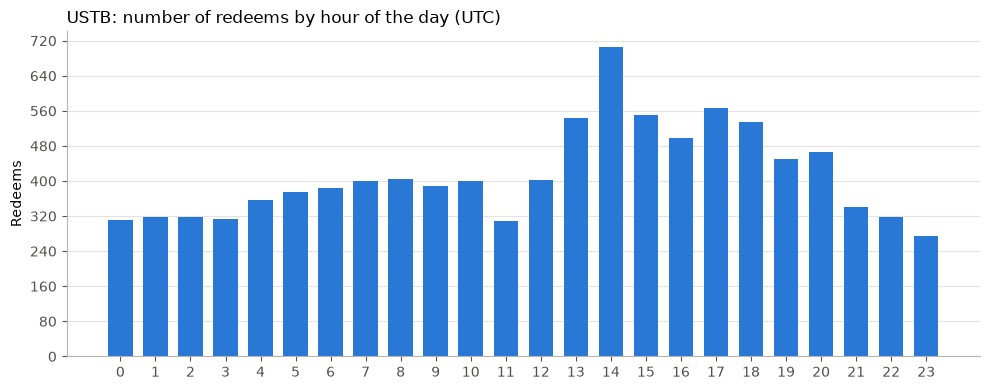

In [7]:
h = hourly("USTB")
bar(h.index.tolist(), h.values, "USTB: number of redeems by hour of the day (UTC)", "Redeems", integer=True)

## USCC (Superstate)

### USCC: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [8]:
overall("USCC")

,Value
Redeems (count),432
Average,$2.5M
Std,$5.7M
Min,$107
P20,$8.8K
P50,$504.5K
P95,$11.3M
P99,$32.4M
Max,$50.3M


### USCC: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [9]:
m = monthly("USCC")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,23,31,0.74,$8.9M,$204.5M
Jan 2026,37,31,1.19,$3.5M,$128.2M
Feb 2026,40,28,1.43,$2.5M,$102.0M
Mar 2026,20,31,0.65,$1.4M,$28.6M
Apr 2026,25,30,0.83,$1.4M,$34.7M
May 2026,20,31,0.65,$1.9M,$38.6M
Jun 2026,60,30,2.00,$1.2M,$72.0M
Jul 2026,36,31,1.16,$1.4M,$49.2M
Aug 2026,8,31,0.26,$885.6K,$7.1M


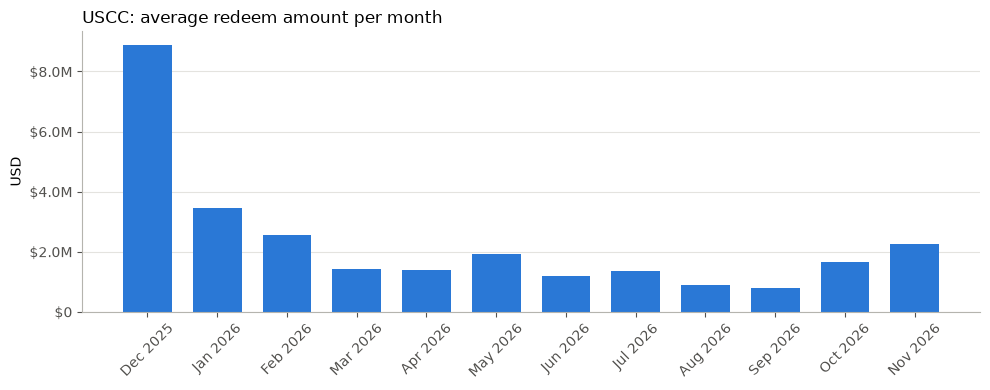

In [10]:
bar(m["label"].tolist(), m["avg_amount_usd"], "USCC: average redeem amount per month", "USD", money=True)

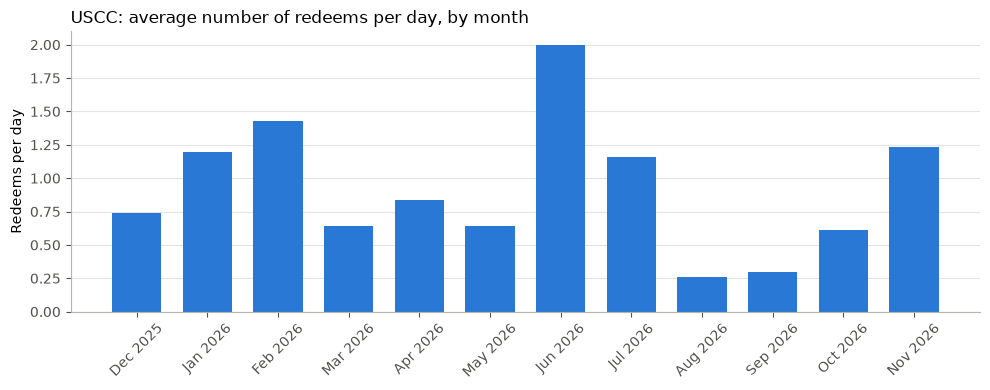

In [11]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "USCC: average number of redeems per day, by month", "Redeems per day")

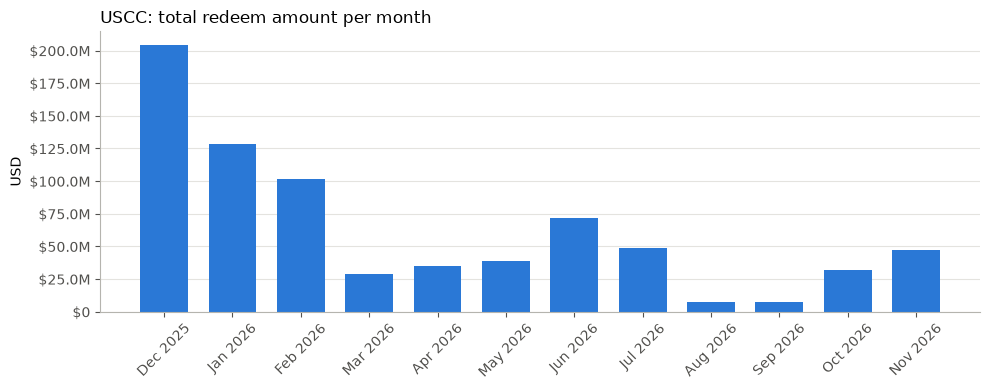

In [12]:
bar(m["label"].tolist(), m["total_amount_usd"], "USCC: total redeem amount per month", "USD", money=True)

### USCC: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

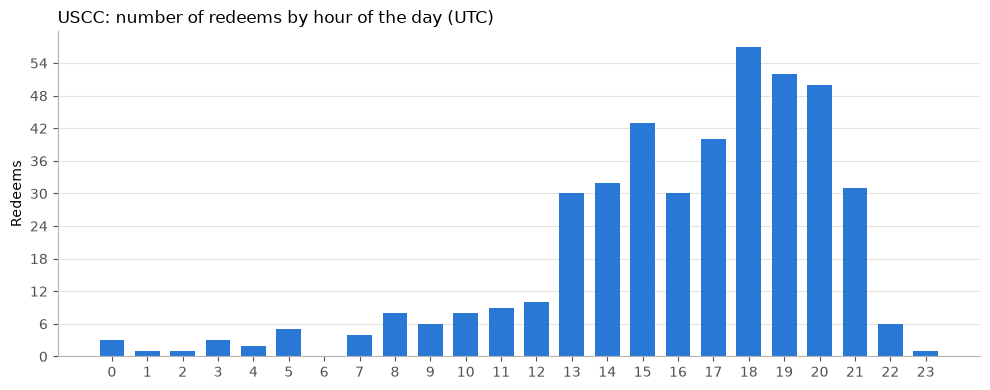

In [13]:
h = hourly("USCC")
bar(h.index.tolist(), h.values, "USCC: number of redeems by hour of the day (UTC)", "Redeems", integer=True)

## mTBILL (Midas)

mTBILL has request redeems and instant redeems. Two Midas vaults supply the data.
Almost all redeems use the vault `0x569D7dccBF6923350521ecBC28A555A500c4f0Ec`.
The file `docs/notes/mtbill-redemptions.md` describes the redeem paths.

Most mTBILL instant redeems do not come from end users.
Other Midas vaults (for example the mEDGE, mMEV, mBASIS and mWIN vaults) redeem mTBILL to pay their own redeems in the same transaction.
These redeems are about 84% of the mTBILL instant amount in USD.
Do not add the mTBILL values to the values of other Midas tokens.

### mTBILL: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [14]:
overall("mTBILL")

,Value
Redeems (count),"3,096"
Average,$46.2K
Std,$271.4K
Min,$100
P20,$213
P50,$1.4K
P95,$184.5K
P99,$901.8K
Max,$8.4M


### mTBILL: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [15]:
m = monthly("mTBILL")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,93,31,3.00,$91.0K,$8.5M
Jan 2026,143,31,4.61,$11.8K,$1.7M
Feb 2026,117,28,4.18,$58.8K,$6.9M
Mar 2026,109,31,3.52,$50.8K,$5.5M
Apr 2026,49,30,1.63,$10.0K,$488.7K
May 2026,96,31,3.10,$77.8K,$7.5M
Jun 2026,29,30,0.97,$59.1K,$1.7M
Jul 2026,41,31,1.32,$212.1K,$8.7M
Aug 2026,32,31,1.03,$147.2K,$4.7M


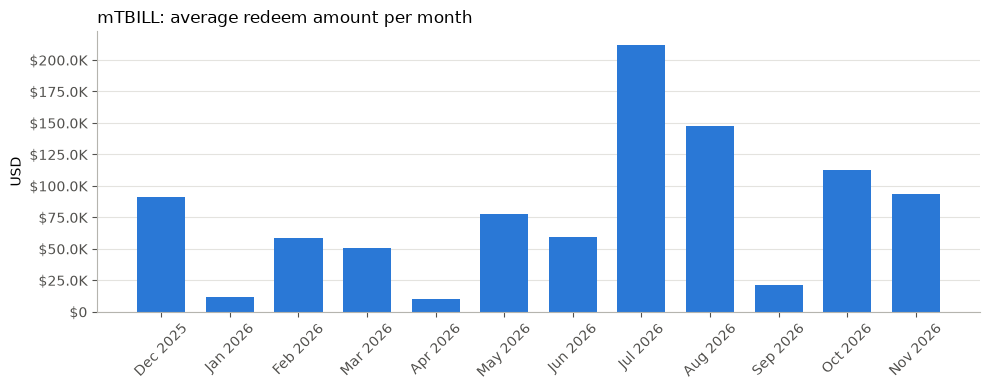

In [16]:
bar(m["label"].tolist(), m["avg_amount_usd"], "mTBILL: average redeem amount per month", "USD", money=True)

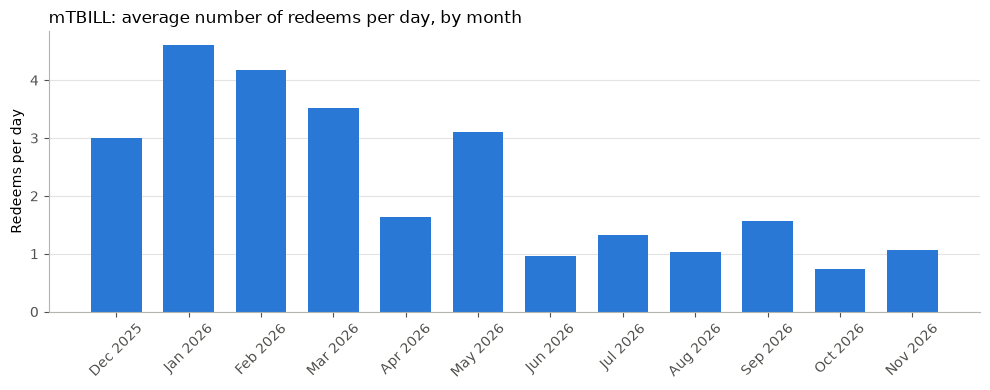

In [17]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "mTBILL: average number of redeems per day, by month", "Redeems per day")

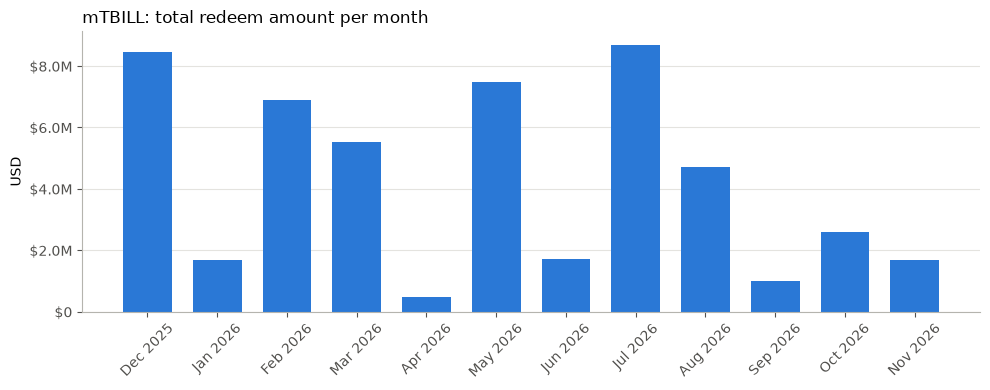

In [18]:
bar(m["label"].tolist(), m["total_amount_usd"], "mTBILL: total redeem amount per month", "USD", money=True)

### mTBILL: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

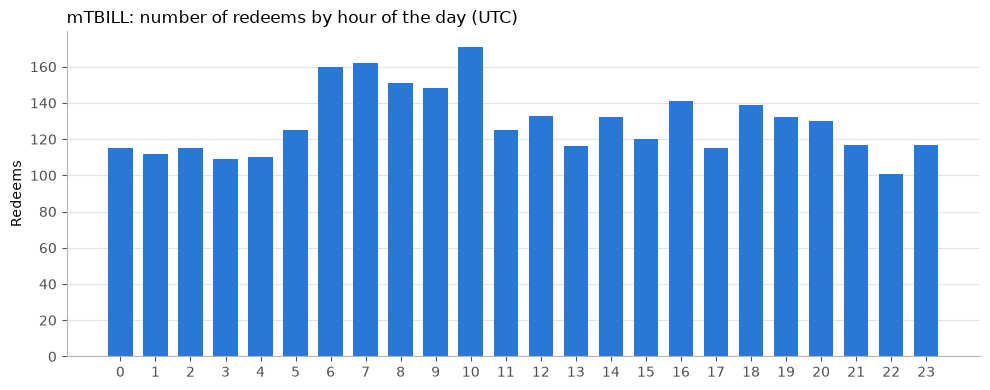

In [19]:
h = hourly("mTBILL")
bar(h.index.tolist(), h.values, "mTBILL: number of redeems by hour of the day (UTC)", "Redeems", integer=True)

## mWIN (Midas)

### mWIN: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [20]:
overall("mWIN")

,Value
Redeems (count),44
Average,$870.5K
Std,$1.1M
Min,$523
P20,$159.4K
P50,$510.2K
P95,$3.5M
P99,$3.9M
Max,$3.9M


### mWIN: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [21]:
m = monthly("mWIN")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,0,31,0.00,-,$0
Jan 2026,0,31,0.00,-,$0
Feb 2026,0,28,0.00,-,$0
Mar 2026,0,31,0.00,-,$0
Apr 2026,0,30,0.00,-,$0
May 2026,0,31,0.00,-,$0
Jun 2026,0,30,0.00,-,$0
Jul 2026,0,31,0.00,-,$0
Aug 2026,4,31,0.13,$392.1K,$1.6M


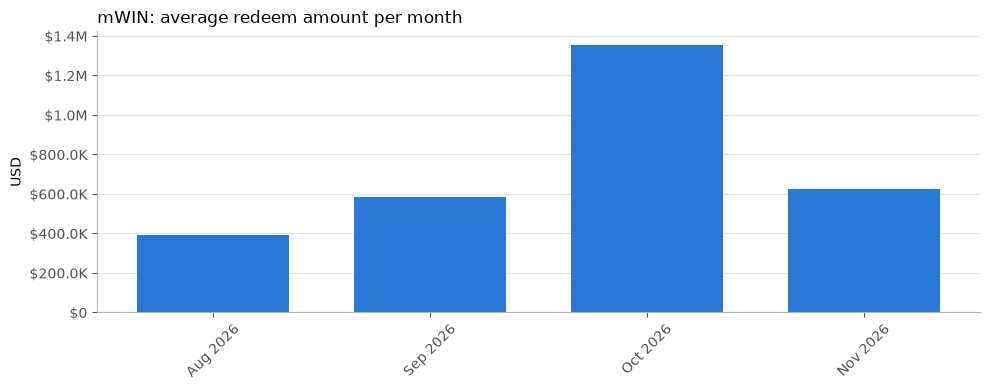

In [22]:
bar(m["label"].tolist(), m["avg_amount_usd"], "mWIN: average redeem amount per month", "USD", money=True)

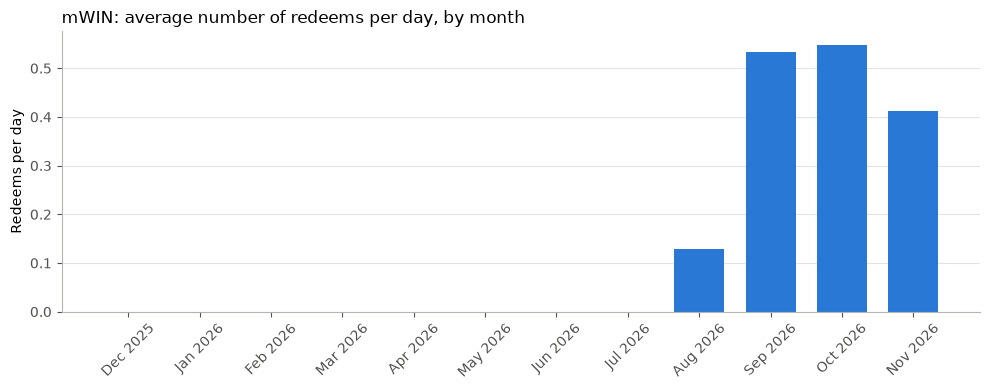

In [23]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "mWIN: average number of redeems per day, by month", "Redeems per day")

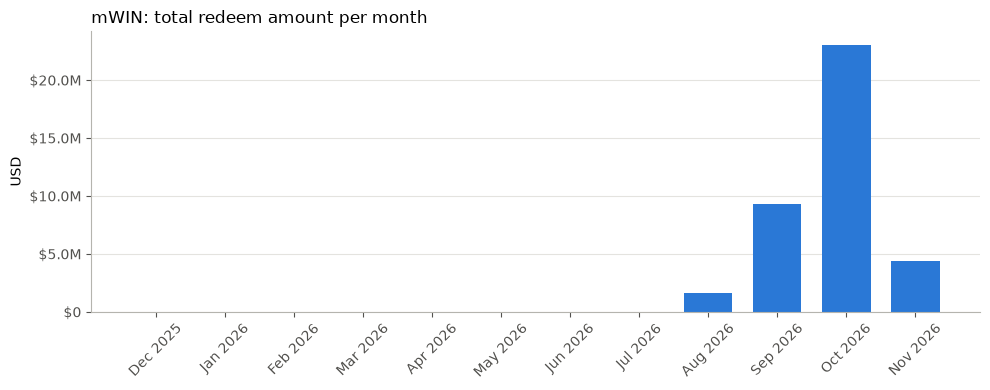

In [24]:
bar(m["label"].tolist(), m["total_amount_usd"], "mWIN: total redeem amount per month", "USD", money=True)

### mWIN: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

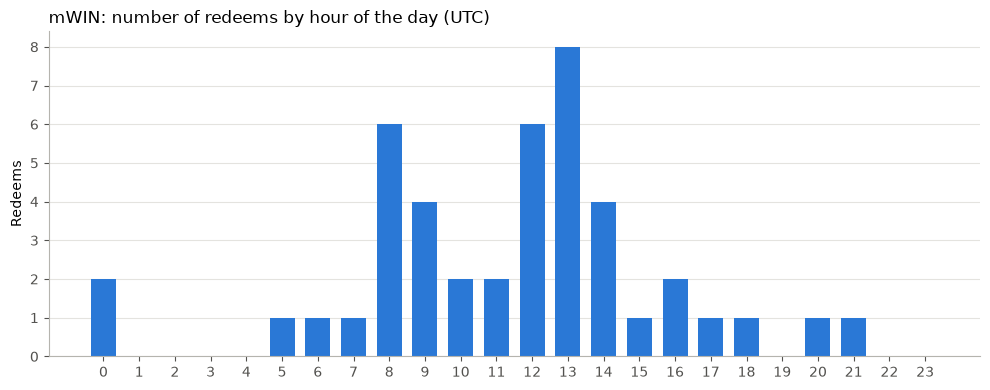

In [25]:
h = hourly("mWIN")
bar(h.index.tolist(), h.values, "mWIN: number of redeems by hour of the day (UTC)", "Redeems", integer=True)

## BUIDL (Securitize)

BUIDL has request redeems and instant redeems. The file `docs/notes/buidl-redemptions.md` describes the redeem paths.

### BUIDL: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [26]:
overall("BUIDL")

,Value
Redeems (count),"1,430"
Average,$1.1M
Std,$7.4M
Min,$100
P20,$1.5K
P50,$10.0K
P95,$5.0M
P99,$16.8M
Max,$194.0M


### BUIDL: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [27]:
m = monthly("BUIDL")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,9,31,0.29,$1.6M,$14.0M
Jan 2026,6,31,0.19,$1.4M,$8.6M
Feb 2026,6,28,0.21,$616.7K,$3.7M
Mar 2026,5,31,0.16,$142.5K,$712.5K
Apr 2026,3,30,0.10,$9.8M,$29.4M
May 2026,3,31,0.10,$1.1M,$3.2M
Jun 2026,3,30,0.10,$316.7K,$950.0K
Jul 2026,2,31,0.06,$675.0K,$1.4M
Aug 2026,3,31,0.10,$5.8M,$17.5M


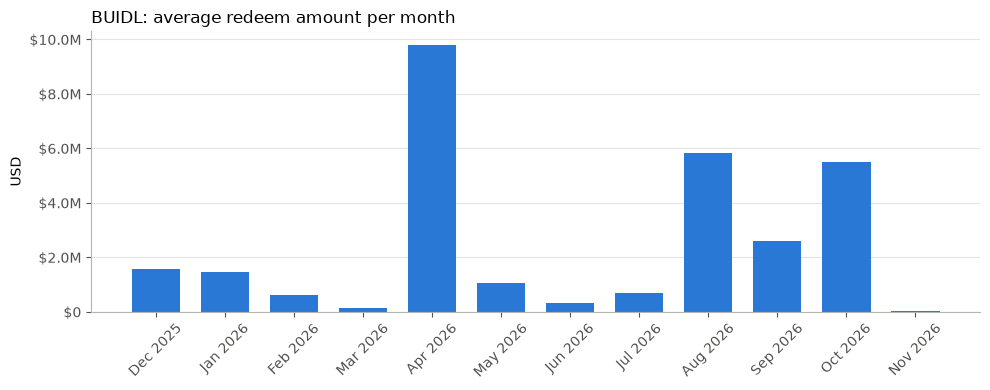

In [28]:
bar(m["label"].tolist(), m["avg_amount_usd"], "BUIDL: average redeem amount per month", "USD", money=True)

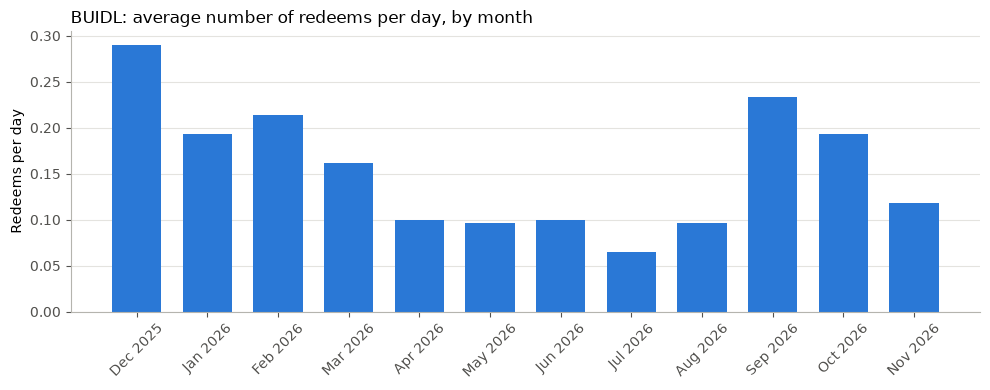

In [29]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "BUIDL: average number of redeems per day, by month", "Redeems per day")

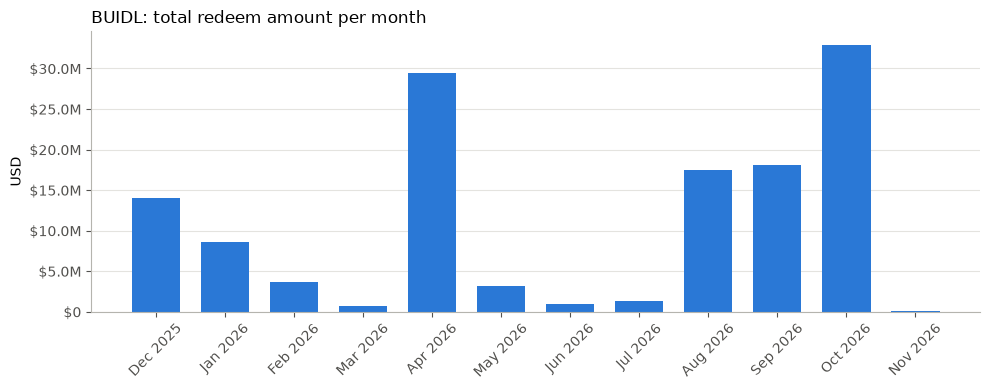

In [30]:
bar(m["label"].tolist(), m["total_amount_usd"], "BUIDL: total redeem amount per month", "USD", money=True)

### BUIDL: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

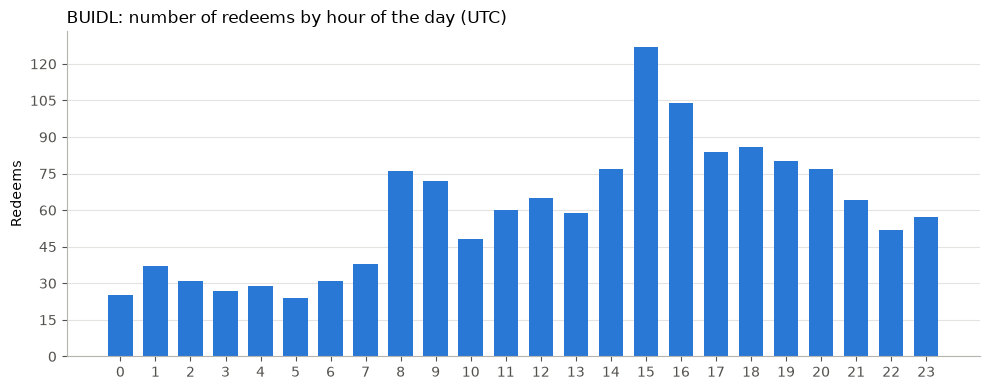

In [31]:
h = hourly("BUIDL")
bar(h.index.tolist(), h.values, "BUIDL: number of redeems by hour of the day (UTC)", "Redeems", integer=True)

## Instant redeems only

This section uses only the instant redeems. These are the rows where `redemption_type` is `instant`.
For each token, the section shows the overall table, the monthly table and three monthly charts.
The data rules at the top of the notebook also apply here.

Instant redeem paths in the data:

- USTB: the Superstate redemption contract pays USDC.
- USCC: the data has no instant redeems.
- mTBILL: the Midas redemption vault pays USDC. If the vault does not have sufficient USDC, it redeems BUIDL (until June 2025) or USTB (after June 2025) in the same transaction.
- mWIN: the Midas redemption vaults pay USDC or PYUSD.
- BUIDL: the Securitize redemption contracts pay USDC or USDtb. The Securitize off-ramp pays RLUSD.

### USTB: instant redeems, overall

The table shows the same values as the USTB overall table, but only for instant redeems.
All values are in USD.

In [32]:
overall("USTB", kind="instant")

,Value
Redeems (count),"8,962"
Average,$150.7K
Std,$513.8K
Min,$100
P20,$1.3K
P50,$13.5K
P95,$678.6K
P99,$2.8M
Max,$8.4M


### USTB: instant redeems, last 12 months

The table shows the monthly values of the instant redeems. Each chart below shows one monthly value.

In [33]:
m = monthly("USTB", kind="instant")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,316,31,10.19,$372.9K,$117.8M
Jan 2026,400,31,12.90,$135.3K,$54.1M
Feb 2026,582,28,20.79,$90.4K,$52.6M
Mar 2026,415,31,13.39,$187.8K,$78.0M
Apr 2026,170,30,5.67,$260.4K,$44.3M
May 2026,331,31,10.68,$187.0K,$61.9M
Jun 2026,527,30,17.57,$148.5K,$78.3M
Jul 2026,496,31,16.00,$236.4K,$117.3M
Aug 2026,632,31,20.39,$140.6K,$88.9M


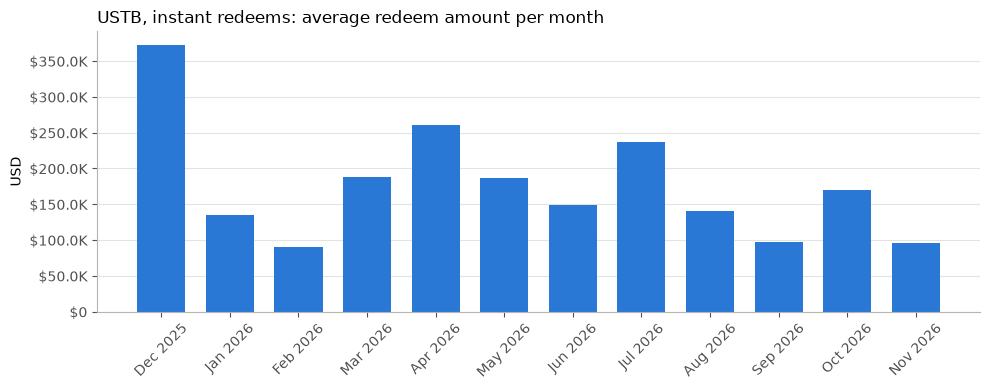

In [34]:
bar(m["label"].tolist(), m["avg_amount_usd"], "USTB, instant redeems: average redeem amount per month", "USD", money=True)

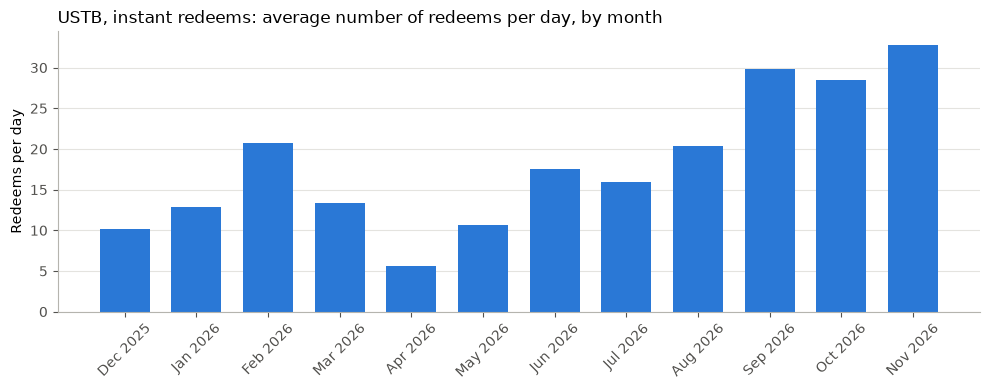

In [35]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "USTB, instant redeems: average number of redeems per day, by month", "Redeems per day")

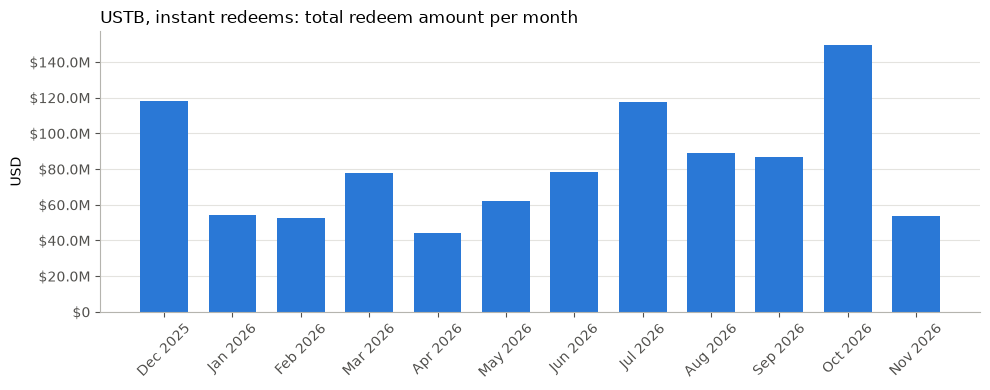

In [36]:
bar(m["label"].tolist(), m["total_amount_usd"], "USTB, instant redeems: total redeem amount per month", "USD", money=True)

### USCC: instant redeems

USCC has no instant redeem path in the data. The cell below shows that the data has no instant redeems for USCC.
Thus this section has no monthly table and no charts for USCC.

In [37]:
overall("USCC", kind="instant")

USCC: the data has no instant redeems of 100 USD or more.


### mTBILL: instant redeems, overall

The table shows the same values as the mTBILL overall table, but only for instant redeems.
All values are in USD.

In [38]:
overall("mTBILL", kind="instant")

,Value
Redeems (count),"3,050"
Average,$44.7K
Std,$271.0K
Min,$100
P20,$211
P50,$1.3K
P95,$168.9K
P99,$883.5K
Max,$8.4M


### mTBILL: instant redeems, last 12 months

The table shows the monthly values of the instant redeems. Each chart below shows one monthly value.

In [39]:
m = monthly("mTBILL", kind="instant")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,92,31,2.97,$91.9K,$8.5M
Jan 2026,143,31,4.61,$11.8K,$1.7M
Feb 2026,115,28,4.11,$59.8K,$6.9M
Mar 2026,107,31,3.45,$39.6K,$4.2M
Apr 2026,48,30,1.60,$9.6K,$460.1K
May 2026,93,31,3.00,$78.1K,$7.3M
Jun 2026,28,30,0.93,$58.3K,$1.6M
Jul 2026,38,31,1.23,$216.5K,$8.2M
Aug 2026,31,31,1.00,$151.6K,$4.7M


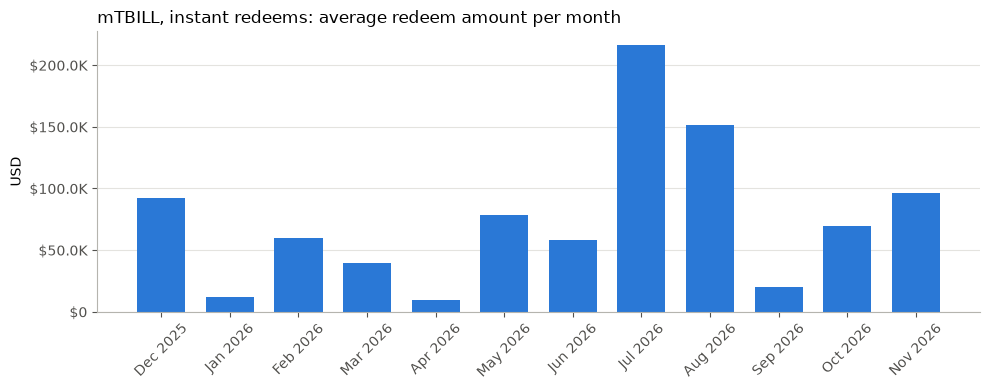

In [40]:
bar(m["label"].tolist(), m["avg_amount_usd"], "mTBILL, instant redeems: average redeem amount per month", "USD", money=True)

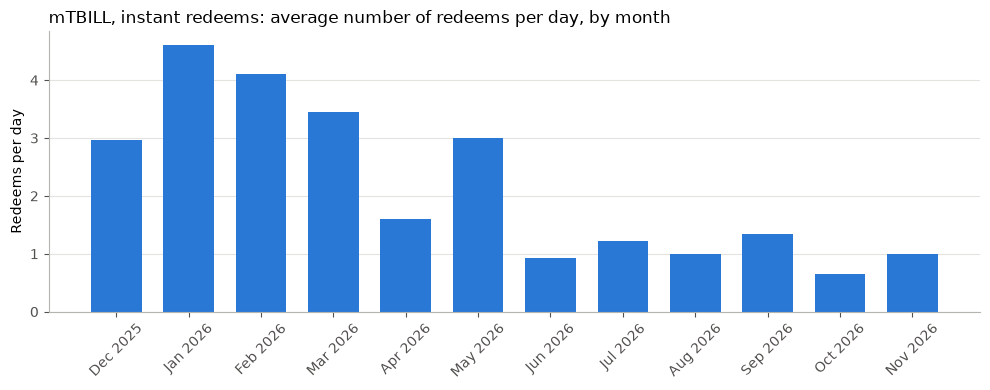

In [41]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "mTBILL, instant redeems: average number of redeems per day, by month", "Redeems per day")

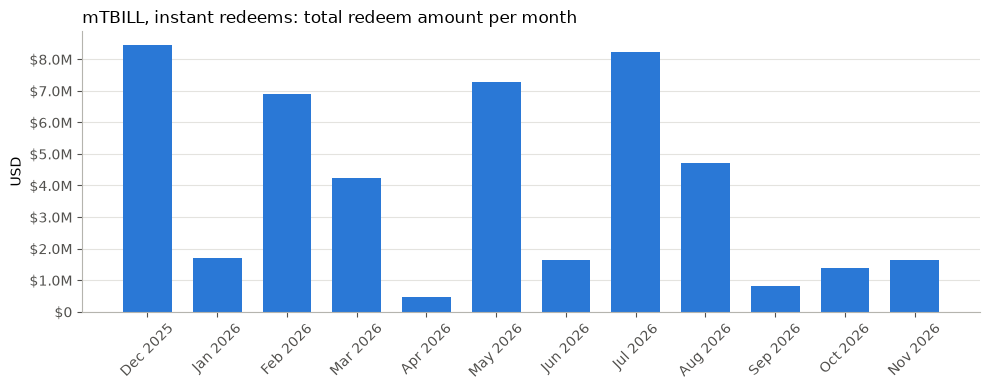

In [42]:
bar(m["label"].tolist(), m["total_amount_usd"], "mTBILL, instant redeems: total redeem amount per month", "USD", money=True)

### mWIN: instant redeems, overall

The table shows the same values as the mWIN overall table, but only for instant redeems.
All values are in USD.

In [43]:
overall("mWIN", kind="instant")

,Value
Redeems (count),12
Average,$342.4K
Std,$245.5K
Min,$1.3K
P20,$142.3K
P50,$298.8K
P95,$745.1K
P99,$752.3K
Max,$754.1K


### mWIN: instant redeems, last 12 months

The table shows the monthly values of the instant redeems. Each chart below shows one monthly value.

In [44]:
m = monthly("mWIN", kind="instant")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,0,31,0.00,-,$0
Jan 2026,0,31,0.00,-,$0
Feb 2026,0,28,0.00,-,$0
Mar 2026,0,31,0.00,-,$0
Apr 2026,0,30,0.00,-,$0
May 2026,0,31,0.00,-,$0
Jun 2026,0,30,0.00,-,$0
Jul 2026,0,31,0.00,-,$0
Aug 2026,0,31,0.00,-,$0


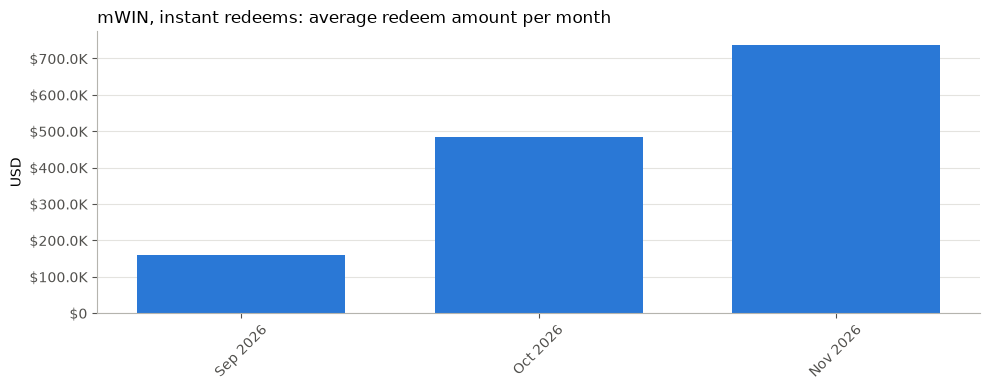

In [45]:
bar(m["label"].tolist(), m["avg_amount_usd"], "mWIN, instant redeems: average redeem amount per month", "USD", money=True)

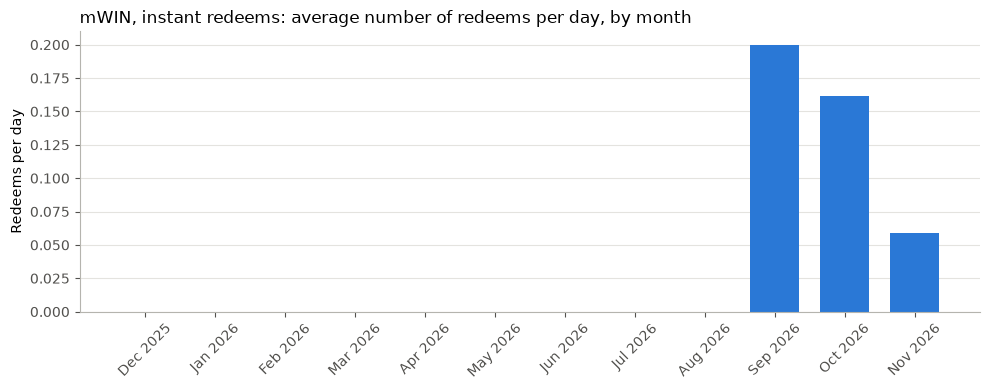

In [46]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "mWIN, instant redeems: average number of redeems per day, by month", "Redeems per day")

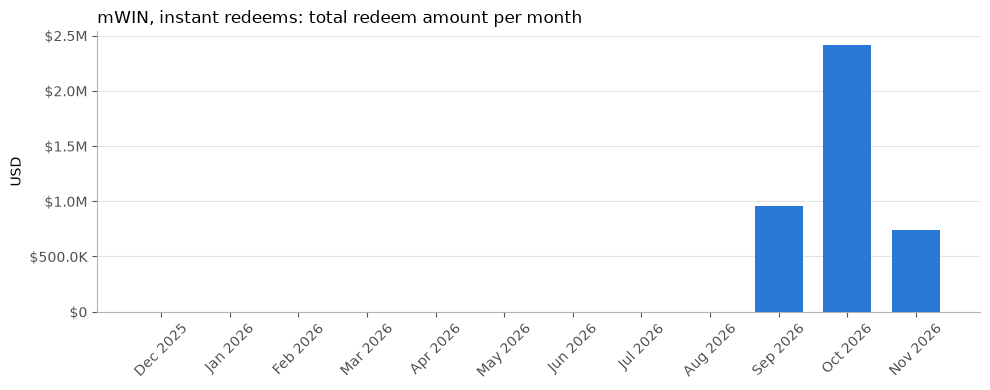

In [47]:
bar(m["label"].tolist(), m["total_amount_usd"], "mWIN, instant redeems: total redeem amount per month", "USD", money=True)

### BUIDL: instant redeems, overall

The table shows the same values as the BUIDL overall table, but only for instant redeems.
All values are in USD.

In [48]:
overall("BUIDL", kind="instant")

,Value
Redeems (count),"1,272"
Average,$391.0K
Std,$1.5M
Min,$100
P20,$1.4K
P50,$7.5K
P95,$1.9M
P99,$8.3M
Max,$15.0M


### BUIDL: instant redeems, last 12 months

The table shows the monthly values of the instant redeems. Each chart below shows one monthly value.

Most BUIDL instant redeems used the USDC redemption contract. The last redeem through that contract was in May 2025, before the last 12 months. Thus the monthly values below show only the redeems through the RLUSD off-ramp.

In [49]:
m = monthly("BUIDL", kind="instant")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,0,31,0.00,-,$0
Jan 2026,2,31,0.06,$1.5M,$3.0M
Feb 2026,2,28,0.07,$600.0K,$1.2M
Mar 2026,0,31,0.00,-,$0
Apr 2026,1,30,0.03,$2.0M,$2.0M
May 2026,2,31,0.06,$350.0K,$700.0K
Jun 2026,1,30,0.03,$250.0K,$250.0K
Jul 2026,0,31,0.00,-,$0
Aug 2026,1,31,0.03,$1.5M,$1.5M


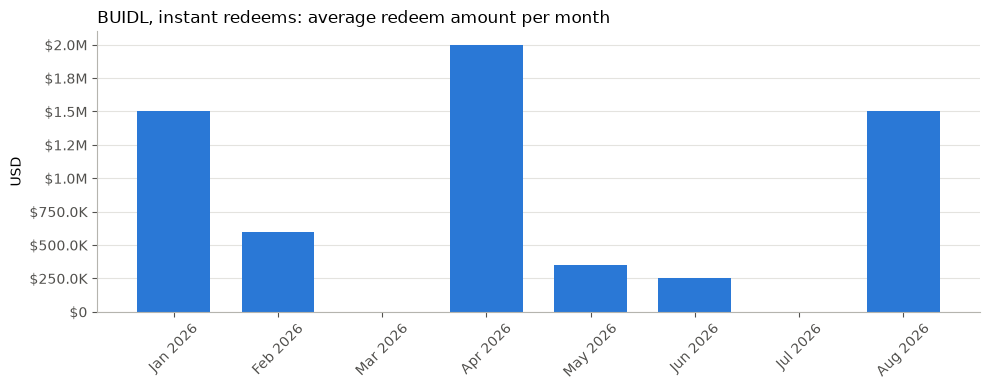

In [50]:
bar(m["label"].tolist(), m["avg_amount_usd"], "BUIDL, instant redeems: average redeem amount per month", "USD", money=True)

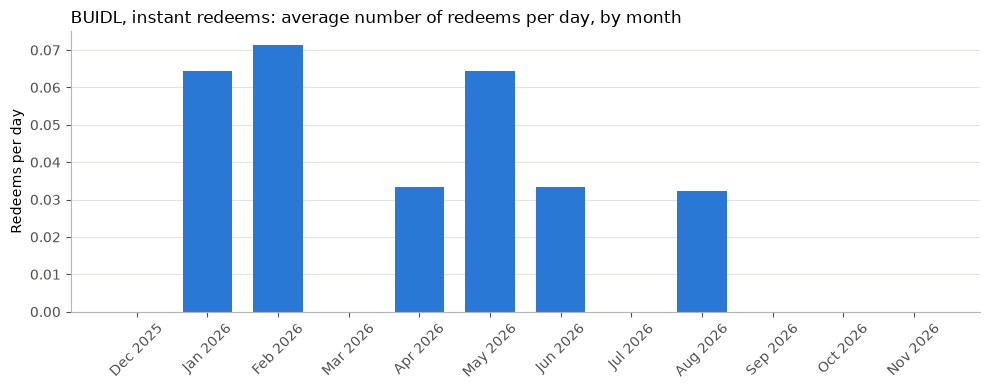

In [51]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "BUIDL, instant redeems: average number of redeems per day, by month", "Redeems per day")

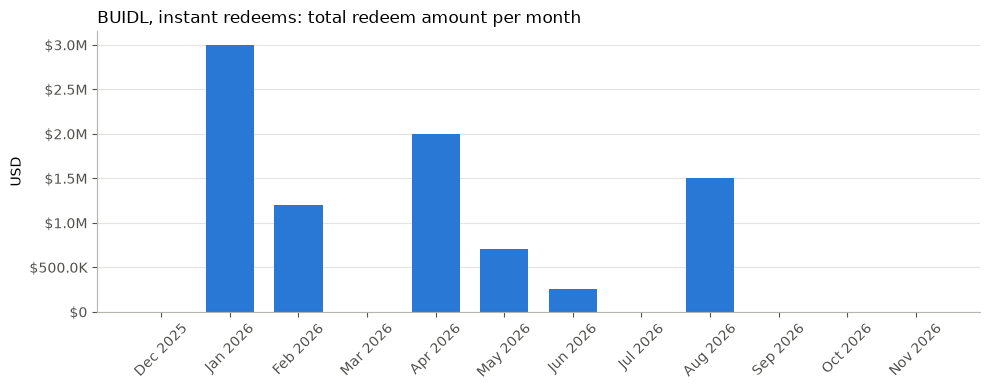

In [52]:
bar(m["label"].tolist(), m["total_amount_usd"], "BUIDL, instant redeems: total redeem amount per month", "USD", money=True)